Run nearest-neighbor analysis on the regional input after the configured magnitude threshold. No earthquakes are selected individually. Small groups are reported, not classified as a particular sequence type. Run this notebook after `00_regional_catalog.ipynb`; it starts a checked workflow session.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / "run_aspect.py").is_file()), None)
assert root is not None, "Open the notebook from within the ASPECT repository."
sys.path.insert(0, str(root / "notebooks"))
import regional_utils as w
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

w.run_stage("nna")
input_magnitudes = pd.read_csv(w.CFG["data_sources"]["QTM"], usecols=["mag"])
threshold = w.CFG["nna_params"]["mag_thresholds"]["QTM"]
nna = pd.read_csv(w.TEXT / "nna_QTM.csv")
nna["datetime"] = pd.to_datetime(nna["datetime"], format="mixed", utc=True)
assert len(nna) == int(input_magnitudes.mag.ge(threshold).sum())
print(f"All-magnitude input: {len(input_magnitudes):,}; NNA cutoff: M ≥ {threshold:g}; below cutoff: {(input_magnitudes.mag < threshold).sum():,}")
groups = (nna.groupby("cluster_id").agg(n_events=("mag", "size"), start=("datetime", "min"),
          end=("datetime", "max"), max_magnitude=("mag", "max"),
          mean_lat=("lat", "mean"), mean_lon=("lon", "mean"))
          .sort_values("n_events", ascending=False))
minimum = w.CFG["min_prelim_size"]
groups["eligible_for_refinement"] = groups.n_events.ge(minimum)
print(f"Total events: {len(nna):,}; preliminary groups: {len(groups):,}")
print(f"Groups with at least {minimum} events: {groups.eligible_for_refinement.sum():,}")
print(f"Events in smaller groups: {groups.loc[~groups.eligible_for_refinement, 'n_events'].sum():,}")
with pd.option_context("display.max_rows", None):
    display(groups[groups.eligible_for_refinement])

--- Processing NNA for QTM ---
[NNA exact_pruned]    10000/80574 events | elapsed   0.01 min
[NNA exact_pruned]    20000/80574 events | elapsed   0.01 min
[NNA exact_pruned]    30000/80574 events | elapsed   0.01 min
[NNA exact_pruned]    40000/80574 events | elapsed   0.02 min
[NNA exact_pruned]    50000/80574 events | elapsed   0.03 min
[NNA exact_pruned]    60000/80574 events | elapsed   0.03 min
[NNA exact_pruned]    70000/80574 events | elapsed   0.04 min
[NNA exact_pruned]    80000/80574 events | elapsed   0.05 min
[NNA exact_pruned]    80574/80574 events | elapsed   0.05 min

Completed nna; inputs and products recorded in regional_notebook_session.json.


All-magnitude input: 288,129; NNA cutoff: M ≥ 0.3; below cutoff: 207,555
Total events: 80,574; preliminary groups: 39,764
Groups with at least 50 events: 85
Events in smaller groups: 60,848


,n_events,start,end,max_magnitude,mean_lat,mean_lon,eligible_for_refinement
cluster_id,,,,,,,
18957.0,2463,2010-07-07 23:53:33.371000+00:00,2015-08-09 22:17:58.910000+00:00,5.43,33.447799,-116.463090,True
38779.0,2387,2013-03-11 16:35:52.196000+00:00,2016-08-29 12:32:57.908000+00:00,4.70,33.505305,-116.460300,True
65256.0,2074,2016-06-10 08:04:36.749000+00:00,2017-12-31 23:31:35.038000+00:00,5.19,33.470511,-116.461058,True
79599.0,1764,2016-08-19 14:15:05.919000+00:00,2017-12-31 23:38:25.454000+00:00,3.48,33.499798,-116.787803,True
14600.0,815,2010-02-13 16:59:06.879000+00:00,2015-09-22 20:11:36.662000+00:00,4.10,34.012527,-117.188605,True
50930.0,574,2014-07-02 00:58:35.066000+00:00,2014-11-13 21:12:41.734000+00:00,2.85,34.034085,-117.161509,True
56130.0,548,2015-02-18 14:57:37.633000+00:00,2017-03-01 16:16:10.051000+00:00,2.44,33.471849,-116.569559,True
18100.0,528,2010-06-13 03:08:57.139000+00:00,2015-12-29 07:22:07.132000+00:00,4.45,33.383293,-116.391978,True
5253.0,381,2008-10-29 02:16:23.094000+00:00,2008-11-15 11:12:03.065000+00:00,3.61,33.065168,-115.891143,True


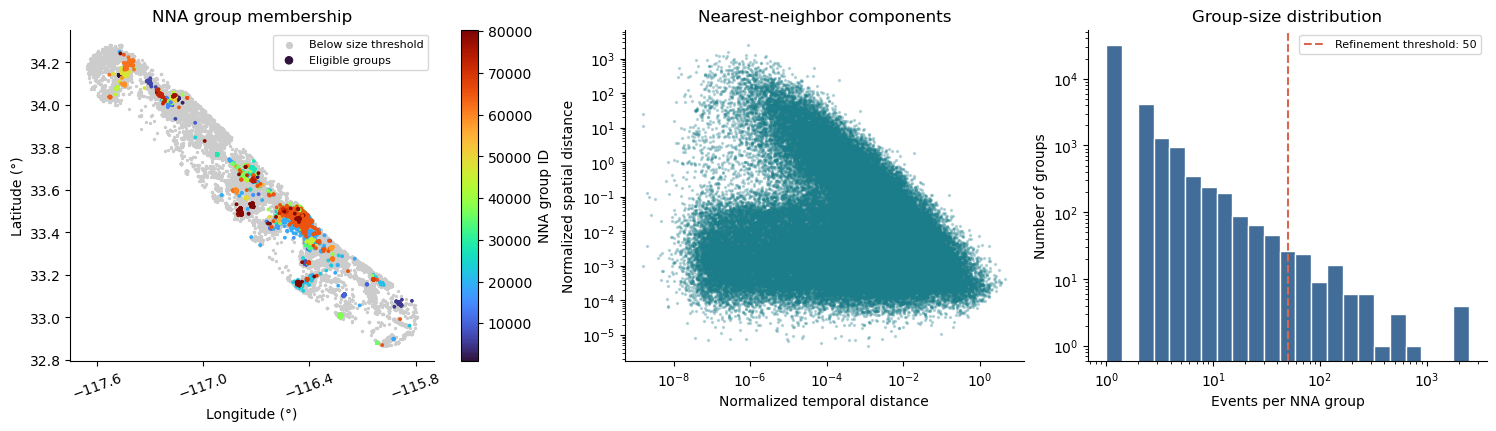

In [2]:
eligible_ids = groups.index[groups.eligible_for_refinement]
eligible = nna.cluster_id.isin(eligible_ids)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
ax[0].scatter(nna.loc[~eligible, "lon"], nna.loc[~eligible, "lat"], s=2, color=".8", rasterized=True, label="Below size threshold")
sc = ax[0].scatter(nna.loc[eligible, "lon"], nna.loc[eligible, "lat"], c=nna.loc[eligible, "cluster_id"], s=3, cmap="turbo", rasterized=True, label="Eligible groups")
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="NNA group membership")
ax[0].set_aspect(1 / np.cos(np.deg2rad(nna.lat.mean())))
ax[0].xaxis.set_major_locator(plt.MaxNLocator(4))
ax[0].tick_params(axis="x", rotation=20)
ax[0].legend(fontsize=8, markerscale=3)
fig.colorbar(sc, ax=ax[0], label="NNA group ID")
valid = nna.TN.gt(0) & nna.RN.gt(0)
ax[1].scatter(nna.loc[valid, "TN"], nna.loc[valid, "RN"], s=2, color="#1b7d89", alpha=.25, rasterized=True)
ax[1].set(xscale="log", yscale="log", xlabel="Normalized temporal distance", ylabel="Normalized spatial distance", title="Nearest-neighbor components")
sizes = groups.n_events.to_numpy()
bins = np.geomspace(1, max(2, sizes.max() + 1), 24)
ax[2].hist(sizes, bins=bins, color="#416d98", edgecolor="white")
ax[2].axvline(minimum, color="#d86751", ls="--", label=f"Refinement threshold: {minimum}")
ax[2].set(xscale="log", yscale="log", xlabel="Events per NNA group", ylabel="Number of groups", title="Group-size distribution")
ax[2].legend(fontsize=8); plt.show()

The figure includes all catalog events and the table includes every group eligible for refinement. The smaller-group counts are listed separately. Proceed to `02_refinement.ipynb`.